In [ ]:
bedtools intersect -f 0.5 -r -a HTY_ovary_H3K27ac.ChIPseeker.annotation.tsv -b HTY_ovary_H3K4me3.ChIPseeker.annotation.tsv -wa -wb > HTY_H3K4me3_H3K27ac_overlap.annotation.tsv
bedtools intersect -v HTY_ovary_H3K27ac.ChIPseeker.annotation.tsv -b HTY_ovary_H3K4me3.ChIPseeker.annotation.tsv -wa > HTY_H3K27ac_specific.annotation.tsv
bedtools intersect -f 0.5 -r -a HY_ovary_H3K27ac.ChIPseeker.annotation.tsv -b HY_ovary_H3K4me3.ChIPseeker.annotation.tsv -wa -wb > HY_H3K4me3_H3K27ac_overlap.annotation.tsv
bedtools intersect -v HY_ovary_H3K27ac.ChIPseeker.annotation.tsv -b HY_ovary_H3K4me3.ChIPseeker.annotation.tsv -wa > HY_H3K27ac_specific.annotation.tsv


In [18]:
import pandas as pd
import pandas as pd 
deg_gene = pd.read_csv('/home/hnadmin/data/yangshuju/result/ovary/RNA_Seq/Significant_DEG_HTY_vs_HY.csv')
hy_deg_gene = list(deg_gene[deg_gene['group']=='Up in HY']['gene'])
hty_deg_gene = list(deg_gene[deg_gene['group']=='Up in HTY']['gene'])

hy_H3K4me3_H3K27ac_overlap = pd.read_csv('/home/hnadmin/data/yangshuju/result/ovary/peak/ChIPseeker_annotation/results/HY_H3K4me3_H3K27ac_overlap.annotation.tsv',sep='\t')
hy_H3K4me3_H3K27ac_overlap = hy_H3K4me3_H3K27ac_overlap[hy_H3K4me3_H3K27ac_overlap['H3K27ac_geneId'].isin(hy_deg_gene)]
hty_H3K4me3_H3K27ac_overlap = pd.read_csv('/home/hnadmin/data/yangshuju/result/ovary/peak/ChIPseeker_annotation/results/HTY_H3K4me3_H3K27ac_overlap.annotation.tsv',sep='\t')
hty_H3K4me3_H3K27ac_overlap = hty_H3K4me3_H3K27ac_overlap[hty_H3K4me3_H3K27ac_overlap['H3K27ac_geneId'].isin(hty_deg_gene)]
hy_H3K4me3_H3K27ac_overlap[hy_H3K4me3_H3K27ac_overlap['H3K27ac_annotation'].str.contains('Promoter')].to_csv('hy_H3K4me3_H3K27ac_overlap_promoter.csv',index=False)
hty_H3K4me3_H3K27ac_overlap[hty_H3K4me3_H3K27ac_overlap['H3K27ac_annotation'].str.contains('Promoter')].to_csv('hty_H3K4me3_H3K27ac_overlap_promoter.csv',index=False)


In [ ]:
import pandas as pd
import re

# ============================================================
# 1. 输入文件
# ============================================================

hty_enhancer_file = (
    "/home/hnadmin/data/yangshuju/result/ovary/peak/"
    "HTY-H3K27ac_enhancer.bed"
)

hy_enhancer_file = (
    "/home/hnadmin/data/yangshuju/result/ovary/peak/"
    "HY-H3K27ac_enhancer.bed"
)

gtf_file = (
    "/home/hnadmin/data/yangshuju/result/ovary/bam/"
    "GCF_000298735.2_Oar_v4.0_genomic.gtf"
)

tpm_file = (
    "/home/hnadmin/data/yangshuju/result/ovary/"
    "TPM_HTY_HY_result.txt"
)

# 输出
output_all = "HTY_HY_differential_enhancer_nearby_genes_TPM.tsv"

output_hty = "HTY_specific_enhancer_nearby_genes_TPM.tsv"

output_hy = "HY_specific_enhancer_nearby_genes_TPM.tsv"

WINDOW = 1_000_000


# ============================================================
# 2. 读取 enhancer BED
# ============================================================

def read_bed(file, prefix):

    bed = pd.read_csv(
        file,
        sep="\t",
        header=None
    )

    print("\nReading:", file)
    print("Columns:", bed.shape[1])
    print("Number of enhancers:", len(bed))

    # BED前三列
    bed = bed.iloc[:, :3].copy()

    bed.columns = [
        "chr",
        "start",
        "end"
    ]

    # enhancer ID
    bed["enhancer_id"] = [
        f"{prefix}_enhancer_{i+1}"
        for i in range(len(bed))
    ]

    bed["group"] = prefix

    return bed


hty = read_bed(
    hty_enhancer_file,
    "HTY"
)

hy = read_bed(
    hy_enhancer_file,
    "HY"
)


# ============================================================
# 3. 找两个品种 enhancer overlap
# ============================================================

print("\nFinding enhancer overlap...")


# 保存 overlap 的 HTY enhancer ID
hty_overlap_ids = set()

# 保存 overlap 的 HY enhancer ID
hy_overlap_ids = set()


# 按染色体处理
for chrom, hty_chr in hty.groupby("chr"):

    hy_chr = hy[
        hy["chr"] == chrom
    ]

    if len(hy_chr) == 0:
        continue

    for _, hty_row in hty_chr.iterrows():

        overlap = hy_chr[
            (hy_chr["start"] < hty_row["end"]) &
            (hy_chr["end"] > hty_row["start"])
        ]

        if len(overlap) > 0:

            hty_overlap_ids.add(
                hty_row["enhancer_id"]
            )

            hy_overlap_ids.update(
                overlap["enhancer_id"]
            )


# ============================================================
# 4. 定义 specific enhancer
# ============================================================

hty_specific = hty[
    ~hty["enhancer_id"].isin(hty_overlap_ids)
].copy()

hy_specific = hy[
    ~hy["enhancer_id"].isin(hy_overlap_ids)
].copy()

shared_hty = hty[
    hty["enhancer_id"].isin(hty_overlap_ids)
].copy()

shared_hy = hy[
    hy["enhancer_id"].isin(hy_overlap_ids)
].copy()


print("\n========================================")
print("Enhancer statistics")
print("========================================")

print("HTY enhancers:", len(hty))

print("HY enhancers:", len(hy))

print("HTY-specific enhancers:", len(hty_specific))

print("HY-specific enhancers:", len(hy_specific))

print("HTY shared enhancers:", len(shared_hty))

print("HY shared enhancers:", len(shared_hy))


# ============================================================
# 5. 读取 GTF
# ============================================================

print("\nReading GTF...")

gtf_columns = [
    "seqname",
    "source",
    "feature",
    "start",
    "end",
    "score",
    "strand",
    "frame",
    "attribute"
]

gtf = pd.read_csv(
    gtf_file,
    sep="\t",
    comment="#",
    header=None,
    names=gtf_columns
)

print("GTF records:", len(gtf))


# ============================================================
# 6. 只保留 gene
# ============================================================

genes = gtf[
    gtf["feature"] == "gene"
].copy()

print("Number of genes:", len(genes))


# ============================================================
# 7. 提取 gene_id / gene_name
# ============================================================

def get_gtf_attribute(attribute, key):

    if pd.isna(attribute):
        return None

    # gene_id "xxx"
    match = re.search(
        rf'{key}\s+"([^"]+)"',
        attribute
    )

    if match:
        return match.group(1)

    # gene_id=xxx
    match = re.search(
        rf'{key}=([^;]+)',
        attribute
    )

    if match:
        return match.group(1)

    return None


genes["gene_id"] = genes["attribute"].apply(
    lambda x: get_gtf_attribute(
        x,
        "gene_id"
    )
)

genes["gene_name"] = genes["attribute"].apply(
    lambda x: get_gtf_attribute(
        x,
        "gene_name"
    )
)


# ============================================================
# 8. gene symbol
# ============================================================

genes["gene_symbol"] = genes["gene_name"]

genes.loc[
    genes["gene_symbol"].isna(),
    "gene_symbol"
] = genes.loc[
    genes["gene_symbol"].isna(),
    "gene_id"
]


# ============================================================
# 9. 计算 TSS
# ============================================================

genes["TSS"] = genes.apply(
    lambda x:
        x["start"]
        if x["strand"] == "+"
        else x["end"],
    axis=1
)


# ============================================================
# 10. 读取 TPM
# ============================================================

print("\nReading TPM...")

gene_tpm = pd.read_csv(
    tpm_file,
    sep="\t"
)

gene_tpm = gene_tpm[
    [
        "Geneid",
        "HTY_mean_TPM",
        "HY_mean_TPM"
    ]
].copy()

print("TPM genes:", len(gene_tpm))


# ============================================================
# 11. TPM gene ID 标准化
# ============================================================

gene_tpm["Geneid"] = (
    gene_tpm["Geneid"]
    .astype(str)
    .str.strip()
)

genes["gene_id"] = (
    genes["gene_id"]
    .astype(str)
    .str.strip()
)

# 如果 TPM gene ID 有 .1 / .2 等版本号
gene_tpm["gene_id_clean"] = (
    gene_tpm["Geneid"]
    .str.replace(
        r"\.\d+$",
        "",
        regex=True
    )
)

genes["gene_id_clean"] = (
    genes["gene_id"]
    .str.replace(
        r"\.\d+$",
        "",
        regex=True
    )
)


# ============================================================
# 12. TPM 合并到 GTF gene
# ============================================================

genes = genes.merge(
    gene_tpm[
        [
            "gene_id_clean",
            "HTY_mean_TPM",
            "HY_mean_TPM"
        ]
    ],
    on="gene_id_clean",
    how="left"
)

print(
    "Genes with TPM:",
    genes["HTY_mean_TPM"].notna().sum()
)


# ============================================================
# 13. 按染色体建立 gene dictionary
# ============================================================

gene_by_chr = {
    chrom: df
    for chrom, df in genes.groupby(
        "seqname"
    )
}


# ============================================================
# 14. enhancer → ±1 Mb genes
# ============================================================

def find_nearby_genes(
    enhancer_df,
    enhancer_type
):

    results = []

    for _, enhancer in enhancer_df.iterrows():

        chrom = enhancer["chr"]

        start = enhancer["start"]

        end = enhancer["end"]

        enhancer_id = enhancer[
            "enhancer_id"
        ]

        # enhancer center
        center = (
            start + end
        ) / 2

        if chrom not in gene_by_chr:
            continue

        chr_genes = gene_by_chr[
            chrom
        ]

        # ----------------------------------------------------
        # ±1 Mb
        # ----------------------------------------------------

        nearby = chr_genes[
            (
                chr_genes["TSS"]
                >= center - WINDOW
            )
            &
            (
                chr_genes["TSS"]
                <= center + WINDOW
            )
        ].copy()

        if len(nearby) == 0:
            continue

        # ----------------------------------------------------
        # distance
        # ----------------------------------------------------

        nearby["distance_to_TSS"] = (
            nearby["TSS"] - center
        )

        nearby["distance_to_TSS_abs"] = (
            nearby["distance_to_TSS"].abs()
        )

        # ----------------------------------------------------
        # relative position
        # ----------------------------------------------------

        nearby["relative_position"] = (
            nearby["distance_to_TSS"]
            .apply(
                lambda x:
                    "upstream"
                    if x < 0
                    else
                    "downstream"
                    if x > 0
                    else
                    "TSS"
            )
        )

        # ----------------------------------------------------
        # enhancer information
        # ----------------------------------------------------

        nearby["enhancer_id"] = (
            enhancer_id
        )

        nearby["enhancer_type"] = (
            enhancer_type
        )

        nearby["enhancer_chr"] = (
            chrom
        )

        nearby["enhancer_start"] = (
            start
        )

        nearby["enhancer_end"] = (
            end
        )

        nearby["enhancer_length"] = (
            end - start
        )

        results.append(
            nearby
        )

    if len(results) == 0:
        return pd.DataFrame()

    result = pd.concat(
        results,
        ignore_index=True
    )

    # 排序
    result = result.sort_values(
        [
            "enhancer_id",
            "distance_to_TSS_abs"
        ]
    )

    return result


# ============================================================
# 15. HTY-specific enhancer
# ============================================================

print("\nFinding genes near HTY-specific enhancers...")

hty_result = find_nearby_genes(
    hty_specific,
    "HTY-specific"
)


# ============================================================
# 16. HY-specific enhancer
# ============================================================

print("\nFinding genes near HY-specific enhancers...")

hy_result = find_nearby_genes(
    hy_specific,
    "HY-specific"
)


# ============================================================
# 17. 合并 HTY + HY
# ============================================================

result = pd.concat(
    [
        hty_result,
        hy_result
    ],
    ignore_index=True
)


# ============================================================
# 18. 计算 TPM log2 fold change
# ============================================================

import numpy as np

result["log2_HTY_HY_TPM"] = np.log2(
    (
        result["HTY_mean_TPM"] + 0.1
    )
    /
    (
        result["HY_mean_TPM"] + 0.1
    )
)


# ============================================================
# 19. 标记基因在哪个品种表达更高
# ============================================================

result["higher_expression"] = np.where(
    result["HTY_mean_TPM"]
    >
    result["HY_mean_TPM"],
    "HTY",
    np.where(
        result["HTY_mean_TPM"]
        <
        result["HY_mean_TPM"],
        "HY",
        "Equal"
    )
)


# ============================================================
# 20. 调整列顺序
# ============================================================

result = result[
    [
        "enhancer_id",
        "enhancer_type",

        "enhancer_chr",
        "enhancer_start",
        "enhancer_end",
        "enhancer_length",

        "gene_id",
        "gene_symbol",
        "strand",
        "TSS",

        "distance_to_TSS",
        "distance_to_TSS_abs",
        "relative_position",

        "HTY_mean_TPM",
        "HY_mean_TPM",

        "log2_HTY_HY_TPM",
        "higher_expression"
    ]
]


# ============================================================
# 21. 保存全部差异 enhancer → nearby gene
# ============================================================

result.to_csv(
    output_all,
    sep="\t",
    index=False
)


# ============================================================
# 22. 分别保存 HTY / HY
# ============================================================

hty_result_final = result[
    result["enhancer_type"]
    == "HTY-specific"
].copy()

hy_result_final = result[
    result["enhancer_type"]
    == "HY-specific"
].copy()


hty_result_final.to_csv(
    output_hty,
    sep="\t",
    index=False
)

hy_result_final.to_csv(
    output_hy,
    sep="\t",
    index=False
)


# ============================================================
# 23. 输出统计
# ============================================================

print("\n========================================")
print("Analysis completed")
print("========================================")

print(
    "HTY enhancers:",
    len(hty)
)

print(
    "HY enhancers:",
    len(hy)
)

print(
    "HTY-specific enhancers:",
    len(hty_specific)
)

print(
    "HY-specific enhancers:",
    len(hy_specific)
)

print(
    "HTY-specific enhancer-gene pairs:",
    len(hty_result_final)
)

print(
    "HY-specific enhancer-gene pairs:",
    len(hy_result_final)
)

print(
    "Unique genes near HTY-specific enhancers:",
    hty_result_final["gene_symbol"].nunique()
)

print(
    "Unique genes near HY-specific enhancers:",
    hy_result_final["gene_symbol"].nunique()
)

print("\nOutput:")
print(output_all)
print(output_hty)
print(output_hy)


Reading: /home/hnadmin/data/yangshuju/result/ovary/peak/HTY-H3K27ac_enhancer.bed
Columns: 3
Number of enhancers: 20015

Reading: /home/hnadmin/data/yangshuju/result/ovary/peak/HY-H3K27ac_enhancer.bed
Columns: 3
Number of enhancers: 22406

Finding enhancer overlap...

Enhancer statistics
HTY enhancers: 20015
HY enhancers: 22406
HTY-specific enhancers: 12477
HY-specific enhancers: 14868
HTY shared enhancers: 7538
HY shared enhancers: 7538

Reading GTF...
GTF records: 1236024
Number of genes: 29300

Reading TPM...
TPM genes: 29300
Genes with TPM: 29302

Finding genes near HTY-specific enhancers...

Finding genes near HY-specific enhancers...

Analysis completed
HTY enhancers: 20015
HY enhancers: 22406
HTY-specific enhancers: 12477
HY-specific enhancers: 14868
HTY-specific enhancer-gene pairs: 292581
HY-specific enhancer-gene pairs: 350098
Unique genes near HTY-specific enhancers: 28512
Unique genes near HY-specific enhancers: 28555

Output:
HTY_HY_differential_enhancer_nearby_genes_TPM.t

breed specific promoter peak bar plot

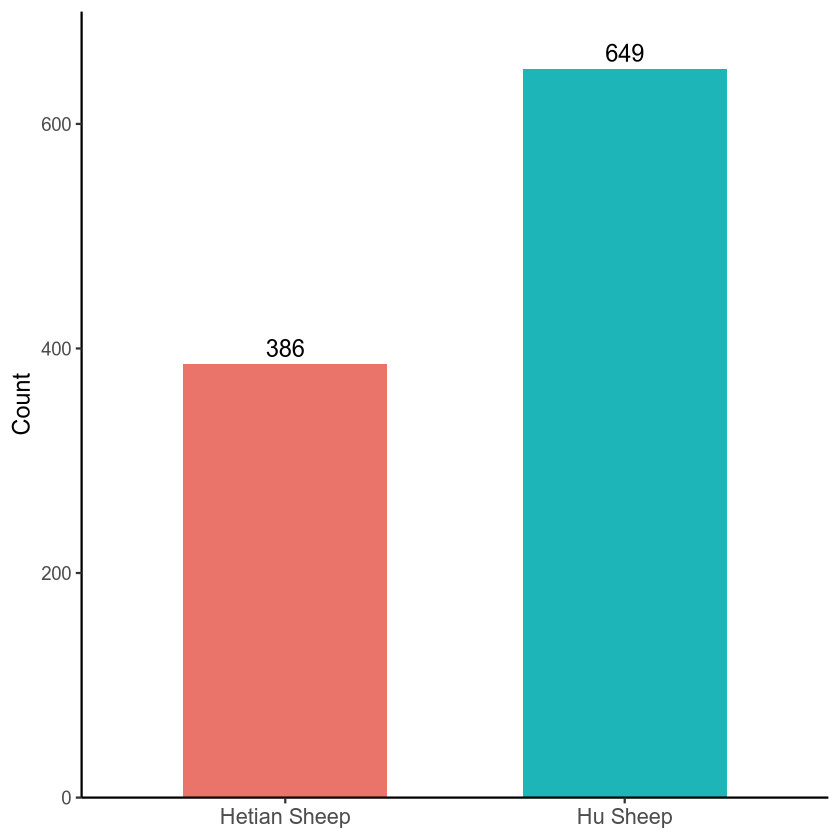

In [6]:
library(ggplot2)

df <- data.frame(
  Sheep = c("Hu Sheep", "Hetian Sheep"),
  Count = c(649, 386)
)

p <- ggplot(df, aes(x = Sheep, y = Count, fill = Sheep)) +
  geom_col(width = 0.6) +
  geom_text(
    aes(label = Count),
    vjust = -0.4,
    size = 5
  ) +
  scale_fill_manual(
    values = c(
      "Hu Sheep" = "#1eb5b8",
      "Hetian Sheep" = "#eb746a"
    )
  ) +
  scale_y_continuous(
    expand = c(0, 0),
    limits = c(0, 700)
  ) +
  labs(
    x = NULL,
    y = "Count"
  ) +
  theme_classic(base_size = 14) +
  theme(
    axis.text.x = element_text(size = 13),
    axis.title.y = element_text(size = 14),
    legend.position = "none"
  )

print(p)

ggsave(
  "Hu_Hetian_count_barplot.pdf",
  p,
  width = 5,
  height = 5
)

breed specific H3K27ac target gene

In [1]:
import pandas as pd
deg = pd.read_csv('/home/hnadmin/data/yangshuju/result/ovary/RNA_Seq/Significant_DEG_HTY_vs_HY.csv')
deg = deg[['gene','group']]
# hy_h3k27ac_nearby_gene = pd.read_csv('/home/hnadmin/data/yangshuju/result/ovary/peak/ChIPseeker_annotation/results/HY_H3K27ac_specific_nearby_genes.tsv',sep='\t')
# hy_breed_specific = pd.read_csv('/home/hnadmin/data/yangshuju/result/ovary/peak/ChIPseeker_annotation/results/HY_HTY_H3K27ac_differential_peak/HY_H3K27ac_breed_specific_peak.bed',sep='\t',names=['chr','start','end','peak_id'])
# hy_h3k27ac_nearby_gene_breed_specific = hy_h3k27ac_nearby_gene[hy_h3k27ac_nearby_gene['peak_id'].isin(hy_breed_specific['peak_id'])]
hy_h3k27ac_nearby_gene_breed_specific = pd.read_csv('/home/hnadmin/data/yangshuju/result/ovary/peak/ChIPseeker_annotation/results/HY_specific_enhancer_nearby_genes_TPM.tsv',sep='\t')
hy_h3k27ac_nearby_gene_breed_specific = pd.merge(hy_h3k27ac_nearby_gene_breed_specific,deg,left_on='gene_id',right_on='gene',how='left')
hy_h3k27ac_nearby_gene_breed_specific.to_csv('/home/hnadmin/data/yangshuju/result/ovary/peak/ChIPseeker_annotation/results/HY_specific_enhancer_nearby_genes_TPM_with_DEG.tsv',sep='\t',index=False)
hy_h3k27ac_nearby_gene_breed_specific = hy_h3k27ac_nearby_gene_breed_specific[hy_h3k27ac_nearby_gene_breed_specific['HY_mean_TPM']>100]



# hty_h3k27ac_nearby_gene = pd.read_csv('/home/hnadmin/data/yangshuju/result/ovary/peak/ChIPseeker_annotation/results/HTY_H3K27ac_specific_nearby_genes.tsv',sep='\t')
# hty_breed_specific = pd.read_csv('/home/hnadmin/data/yangshuju/result/ovary/peak/ChIPseeker_annotation/results/HY_HTY_H3K27ac_differential_peak/HTY_H3K27ac_breed_specific_peak.bed',sep='\t',names=['chr','start','end','peak_id'])
# hty_h3k27ac_nearby_gene_breed_specific = hty_h3k27ac_nearby_gene[hty_h3k27ac_nearby_gene['peak_id'].isin(hty_breed_specific['peak_id'])]
hty_h3k27ac_nearby_gene_breed_specific = pd.read_csv('/home/hnadmin/data/yangshuju/result/ovary/peak/ChIPseeker_annotation/results/HTY_specific_enhancer_nearby_genes_TPM.tsv',sep='\t')
hty_h3k27ac_nearby_gene_breed_specific = pd.merge(hty_h3k27ac_nearby_gene_breed_specific,deg,left_on='gene_id',right_on='gene',how='left')
hty_h3k27ac_nearby_gene_breed_specific.to_csv('/home/hnadmin/data/yangshuju/result/ovary/peak/ChIPseeker_annotation/results/HTY_specific_enhancer_nearby_genes_TPM_with_DEG.tsv',sep='\t',index=False)
hty_h3k27ac_nearby_gene_breed_specific = hty_h3k27ac_nearby_gene_breed_specific[hty_h3k27ac_nearby_gene_breed_specific['HTY_mean_TPM']>100]

In [26]:
hy_100kb = hy_h3k27ac_nearby_gene_breed_specific[hy_h3k27ac_nearby_gene_breed_specific['distance_to_TSS_abs']<100000]
hy_200kb = hy_h3k27ac_nearby_gene_breed_specific[hy_h3k27ac_nearby_gene_breed_specific['distance_to_TSS_abs']<200000]
hy_500kb = hy_h3k27ac_nearby_gene_breed_specific[hy_h3k27ac_nearby_gene_breed_specific['distance_to_TSS_abs']<500000]
print(len(set(hy_100kb['gene_id'])))
print(len(set(hy_200kb['gene_id'])))
print(len(set(hy_500kb['gene_id'])))
print(len(set(hy_h3k27ac_nearby_gene_breed_specific['gene_id'])))
#hy_200kb = hy_h3k27ac_nearby_gene_breed_specific[hy_h3k27ac_nearby_gene_breed_specific['distance_to_TSS_abs']<200000]

548
712
771
776


In [ ]:
hy_100kb_count = hy_100kb['gene_id'].value_counts().reset_index()
hy_100kb_count[hy_100kb_count['count']>=3]

,gene_id,count
0,TAF10,6
1,RPS7,5
2,LOC101122329,5
3,RANBP1,5
4,TPRG1L,5
...,...,...
115,LOC105609918,3
116,LOC101116631,3
117,LOC101108817,3
118,EDF1,3


In [27]:
hty_100kb = hty_h3k27ac_nearby_gene_breed_specific[hty_h3k27ac_nearby_gene_breed_specific['distance_to_TSS_abs']<100000]
hty_200kb = hty_h3k27ac_nearby_gene_breed_specific[hty_h3k27ac_nearby_gene_breed_specific['distance_to_TSS_abs']<200000]
hty_500kb = hty_h3k27ac_nearby_gene_breed_specific[hty_h3k27ac_nearby_gene_breed_specific['distance_to_TSS_abs']<500000]
print(len(set(hty_100kb['gene_id'])))
print(len(set(hty_200kb['gene_id'])))
print(len(set(hty_500kb['gene_id'])))
print(len(set(hty_h3k27ac_nearby_gene_breed_specific['gene_id'])))

657
908
1052
1066


In [15]:
hty_h3k27ac_nearby_gene_breed_specific.to_csv('hty_h3k27ac_nearby_breed_specific_gene.csv',index=False)
hy_h3k27ac_nearby_gene_breed_specific.to_csv('hy_h3k27ac_nearby_breed_specific_gene.csv',index=False)

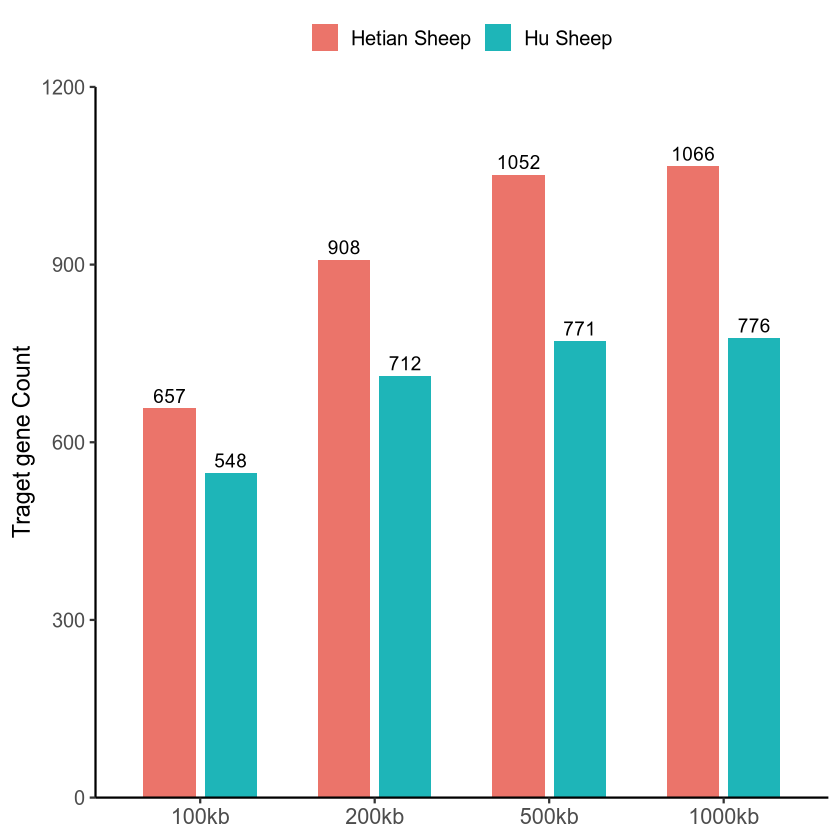

In [ ]:
library(ggplot2)

df <- data.frame(
  Sheep = c(
    rep("Hu Sheep", 4),
    rep("Hetian Sheep", 4)
  ),
  Window = c(
    "100kb", "200kb", "500kb", "1000kb",
    "100kb", "200kb", "500kb", "1000kb"
  ),
  Count = c(
    548,712,771,776,
    657,908,1052,1066
  )
)

# 设置 Window 顺序
df$Window <- factor(
  df$Window,
  levels = c("100kb", "200kb", "500kb", "1000kb")
)

p <- ggplot(
  df,
  aes(
    x = Window,
    y = Count,
    fill = Sheep
  )
) +
  geom_col(
    position = position_dodge(width = 0.7),
    width = 0.6
  ) +
  geom_text(
    aes(label = Count),
    position = position_dodge(width = 0.7),
    vjust = -0.4,
    size = 4
  ) +
  scale_fill_manual(
    values = c(
      "Hu Sheep" = "#1eb5b8",
      "Hetian Sheep" = "#eb746a"
    )
  ) +
  scale_y_continuous(
    expand = c(0, 0),
    limits = c(0, 1200)
  ) +
  labs(
    x = NULL,
    y = "Traget gene Count",
    fill = NULL
  ) +
  theme_classic(base_size = 14) +
  theme(
    axis.text.x = element_text(
      size = 13
    ),
    axis.text.y = element_text(
      size = 12
    ),
    axis.title.y = element_text(
      size = 14
    ),
    legend.position = "top",
    legend.text = element_text(
      size = 12
    )
  )

print(p)

ggsave(
  "Hu_Hetian_window_count_barplot_100TPM.pdf",
  p,
  width = 7,
  height = 5
)

In [6]:
library(eulerr)
library(grid)

venn_data <- c(
  "Hetian Sheep" = 12477,
  "Hu Sheep" = 14868,
  "Hetian Sheep&Hu Sheep" = 7538
)

fit <- euler(venn_data)

pdf('HTY_HY_Enhancer_Venn.pdf')
plot(
  fit,
  fills = c("#1eb5b8", "#eb746a"),
  alpha = 0.55,
  edges = TRUE,
  edge_width = 1,
  quantities = list(
    cex = 1.3,
    font = 2
  ),
  labels = list(
    cex = 1.2,
    font = 2
  )
)
dev.off()

pdf 
  2

In [1]:
library(eulerr)
library(grid)

venn_data <- c(
  "Hetian Sheep" = 386,
  "Hu Sheep" = 639,
  "Hetian Sheep&Hu Sheep" = 362
)

fit <- euler(venn_data)

pdf('HTY_HY_Promoter_Venn.pdf')
plot(
  fit,
  fills = c("#1eb5b8", "#eb746a"),
  alpha = 0.55,
  edges = TRUE,
  edge_width = 1,
  quantities = list(
    cex = 1.3,
    font = 2
  ),
  labels = list(
    cex = 1.2,
    font = 2
  )
)
dev.off()

pdf 
  2

In [4]:
import pandas as pd
import os
import re

# ============================================================
# 1. Input files
# ============================================================

gwas_file = "/home/hnadmin/data/yangshuju/result/ovary/peak/ChIPseeker_annotation/results/peak_gene_annotation_gwas.tsv"

hty_file = "/home/hnadmin/data/yangshuju/result/ovary/peak/ChIPseeker_annotation/results/HTY_specific_enhancer_nearby_genes_TPM_with_DEG.tsv"

hy_file = "/home/hnadmin/data/yangshuju/result/ovary/peak/ChIPseeker_annotation/results/HY_specific_enhancer_nearby_genes_TPM_with_DEG.tsv"

outdir = "/home/hnadmin/data/yangshuju/result/ovary/peak/ChIPseeker_annotation/results/SNP_peak_gene_overlap"

os.makedirs(outdir, exist_ok=True)


# ============================================================
# 2. Read GWAS annotation
#    GWAS file has NO header
# ============================================================

gwas = pd.read_csv(
    gwas_file,
    sep="\t",
    header=None
)

gwas.columns = [
    "peak_chr",
    "peak_start",
    "peak_end",
    "peak_length",
    "strand",
    "annotation",
    "distance_to_TSS",
    "gene_start",
    "gene_end",
    "gene_length",
    "exon_rank",
    "gene_symbol",
    "distance_to_peak",
    "peak_id",
    "snp_chr",
    "snp_start",
    "snp_end"
]

print("GWAS:")
print(gwas.shape)
print(gwas.head())


# ============================================================
# 3. Read enhancer files
# ============================================================

hty = pd.read_csv(hty_file, sep="\t")
hy = pd.read_csv(hy_file, sep="\t")

print("\nHTY enhancer:")
print(hty.shape)

print("\nHY enhancer:")
print(hy.shape)


# ============================================================
# 4. Clean chromosome names
# ============================================================

def clean_chr(x):

    x = str(x).strip()

    # NC_019466.2.1 -> NC_019466.2
    # 只删除最后一个 .数字
    x = re.sub(r"\.\d+$", "", x)

    return x


gwas["snp_chr_clean"] = gwas["snp_chr"].apply(clean_chr)

hty["enhancer_chr_clean"] = hty["enhancer_chr"].apply(clean_chr)

hy["enhancer_chr_clean"] = hy["enhancer_chr"].apply(clean_chr)


# ============================================================
# 5. Make sure coordinates are numeric
# ============================================================

gwas["snp_start"] = pd.to_numeric(
    gwas["snp_start"],
    errors="coerce"
)

gwas["snp_end"] = pd.to_numeric(
    gwas["snp_end"],
    errors="coerce"
)

hty["enhancer_start"] = pd.to_numeric(
    hty["enhancer_start"],
    errors="coerce"
)

hty["enhancer_end"] = pd.to_numeric(
    hty["enhancer_end"],
    errors="coerce"
)

hy["enhancer_start"] = pd.to_numeric(
    hy["enhancer_start"],
    errors="coerce"
)

hy["enhancer_end"] = pd.to_numeric(
    hy["enhancer_end"],
    errors="coerce"
)


# ============================================================
# 6. Remove invalid coordinates
# ============================================================

gwas = gwas.dropna(
    subset=[
        "snp_chr_clean",
        "snp_start",
        "snp_end"
    ]
).copy()

hty = hty.dropna(
    subset=[
        "enhancer_chr_clean",
        "enhancer_start",
        "enhancer_end"
    ]
).copy()

hy = hy.dropna(
    subset=[
        "enhancer_chr_clean",
        "enhancer_start",
        "enhancer_end"
    ]
).copy()


# ============================================================
# 7. IMPORTANT:
#    SNP coordinate is already BED-like:
#
#    14363010 - 14363011
#
#    Therefore directly use these coordinates.
# ============================================================

gwas_snp = gwas[
    [
        "snp_chr_clean",
        "snp_start",
        "snp_end",
        "peak_chr",
        "peak_start",
        "peak_end",
        "peak_id",
        "annotation",
        "gene_symbol",
        "distance_to_peak"
    ]
].copy()


# ============================================================
# 8. Use PyRanges
# ============================================================

try:
    import pyranges as pr
except ImportError:

    print("\nPyRanges is not installed.")
    print("Please install:")
    print("conda install -c bioconda pyranges")

    raise


# ============================================================
# 9. Create SNP PyRanges
# ============================================================

snp_gr = pr.PyRanges(
    pd.DataFrame({
        "Chromosome": gwas_snp["snp_chr_clean"],
        "Start": gwas_snp["snp_start"].astype(int),
        "End": gwas_snp["snp_end"].astype(int),
        "GWAS_peak_id": gwas_snp["peak_id"].astype(str),
        "GWAS_peak_chr": gwas_snp["peak_chr"],
        "GWAS_peak_start": gwas_snp["peak_start"],
        "GWAS_peak_end": gwas_snp["peak_end"],
        "GWAS_gene": gwas_snp["gene_symbol"],
        "GWAS_annotation": gwas_snp["annotation"],
        "GWAS_distance_to_peak": gwas_snp["distance_to_peak"]
    })
)


# ============================================================
# 10. Function:
#     SNP -> enhancer genomic overlap
# ============================================================

def find_snp_enhancer_overlap(
    snp_gr,
    enhancer_df,
    breed
):

    enhancer_gr = pr.PyRanges(
        pd.DataFrame({
            "Chromosome": enhancer_df["enhancer_chr_clean"],
            "Start": enhancer_df["enhancer_start"].astype(int),
            "End": enhancer_df["enhancer_end"].astype(int),

            "enhancer_id": enhancer_df["enhancer_id"].astype(str),

            "enhancer_type": enhancer_df["enhancer_type"],

            "enhancer_chr": enhancer_df["enhancer_chr"],
            "enhancer_start": enhancer_df["enhancer_start"],
            "enhancer_end": enhancer_df["enhancer_end"],

            "gene_id": enhancer_df["gene_id"],
            "gene_symbol": enhancer_df["gene_symbol"],

            "strand": enhancer_df["strand"],
            "TSS": enhancer_df["TSS"],

            "distance_to_TSS": enhancer_df["distance_to_TSS"],
            "distance_to_TSS_abs": enhancer_df["distance_to_TSS_abs"],

            "relative_position": enhancer_df["relative_position"],

            "HTY_mean_TPM": enhancer_df["HTY_mean_TPM"],
            "HY_mean_TPM": enhancer_df["HY_mean_TPM"],

            "log2_HTY_HY_TPM": enhancer_df["log2_HTY_HY_TPM"],

            "higher_expression": enhancer_df["higher_expression"],

            "gene": enhancer_df["gene"],
            "group": enhancer_df["group"]
        })
    )

    # --------------------------------------------------------
    # SNP overlaps enhancer
    # --------------------------------------------------------

    overlap = snp_gr.join(
        enhancer_gr
    )

    result = overlap.df.copy()

    result["Breed_specific"] = breed

    return result


# ============================================================
# 11. HY overlap
# ============================================================

print("\n======================================")
print("Searching HY-specific enhancers...")
print("======================================")

hy_result = find_snp_enhancer_overlap(
    snp_gr,
    hy,
    "HY"
)

print(
    "HY SNP-enhancer overlaps:",
    len(hy_result)
)

print(
    "HY enhancers:",
    hy_result["enhancer_id"].nunique()
    if len(hy_result) > 0 else 0
)

print(
    "HY target genes:",
    hy_result["gene_symbol"].nunique()
    if len(hy_result) > 0 else 0
)


# ============================================================
# 12. HTY overlap
# ============================================================

print("\n======================================")
print("Searching HTY-specific enhancers...")
print("======================================")

hty_result = find_snp_enhancer_overlap(
    snp_gr,
    hty,
    "HTY"
)

print(
    "HTY SNP-enhancer overlaps:",
    len(hty_result)
)

print(
    "HTY enhancers:",
    hty_result["enhancer_id"].nunique()
    if len(hty_result) > 0 else 0
)

print(
    "HTY target genes:",
    hty_result["gene_symbol"].nunique()
    if len(hty_result) > 0 else 0
)


# ============================================================
# 13. Save HY result
# ============================================================

hy_out = os.path.join(
    outdir,
    "HY_specific_GWAS_SNP_enhancer_target_gene.tsv"
)

hy_result.to_csv(
    hy_out,
    sep="\t",
    index=False
)


# ============================================================
# 14. Save HTY result
# ============================================================

hty_out = os.path.join(
    outdir,
    "HTY_specific_GWAS_SNP_enhancer_target_gene.tsv"
)

hty_result.to_csv(
    hty_out,
    sep="\t",
    index=False
)


# ============================================================
# 15. Combine
# ============================================================

all_result = pd.concat(
    [
        hy_result,
        hty_result
    ],
    ignore_index=True
)

all_out = os.path.join(
    outdir,
    "HY_HTY_GWAS_SNP_enhancer_target_gene.tsv"
)

all_result.to_csv(
    all_out,
    sep="\t",
    index=False
)


# ============================================================
# 16. Unique SNP-enhancer-gene relationships
# ============================================================

if len(all_result) > 0:

    unique_result = all_result[
        [
            "Chromosome",
            "Start",
            "End",
            "GWAS_peak_id",
            "enhancer_id",
            "Breed_specific",
            "gene_symbol",
            "gene_id",
            "HTY_mean_TPM",
            "HY_mean_TPM",
            "log2_HTY_HY_TPM",
            "higher_expression",
            "group"
        ]
    ].drop_duplicates()

    unique_out = os.path.join(
        outdir,
        "HY_HTY_GWAS_SNP_enhancer_gene_unique.tsv"
    )

    unique_result.to_csv(
        unique_out,
        sep="\t",
        index=False
    )


# ============================================================
# 17. Gene lists
# ============================================================

hy_genes = set(
    hy_result["gene_symbol"]
    .dropna()
    .astype(str)
)

hty_genes = set(
    hty_result["gene_symbol"]
    .dropna()
    .astype(str)
)

common_genes = hy_genes & hty_genes

hy_specific_genes = hy_genes - hty_genes

hty_specific_genes = hty_genes - hy_genes


pd.DataFrame(
    sorted(hy_genes),
    columns=["gene_symbol"]
).to_csv(
    os.path.join(
        outdir,
        "HY_GWAS_SNP_enhancer_target_genes.txt"
    ),
    sep="\t",
    index=False
)


pd.DataFrame(
    sorted(hty_genes),
    columns=["gene_symbol"]
).to_csv(
    os.path.join(
        outdir,
        "HTY_GWAS_SNP_enhancer_target_genes.txt"
    ),
    sep="\t",
    index=False
)


pd.DataFrame(
    sorted(common_genes),
    columns=["gene_symbol"]
).to_csv(
    os.path.join(
        outdir,
        "HY_HTY_common_GWAS_SNP_enhancer_target_genes.txt"
    ),
    sep="\t",
    index=False
)


# ============================================================
# 18. Summary
# ============================================================

print("\n")
print("======================================")
print("FINAL SUMMARY")
print("======================================")

print(
    "GWAS SNPs:",
    gwas_snp[
        [
            "snp_chr_clean",
            "snp_start",
            "snp_end"
        ]
    ].drop_duplicates().shape[0]
)

print("\nHY:")
print(
    "  SNP-enhancer overlaps:",
    len(hy_result)
)

print(
    "  unique enhancers:",
    hy_result["enhancer_id"].nunique()
    if len(hy_result) else 0
)

print(
    "  target genes:",
    len(hy_genes)
)

print("\nHTY:")
print(
    "  SNP-enhancer overlaps:",
    len(hty_result)
)

print(
    "  unique enhancers:",
    hty_result["enhancer_id"].nunique()
    if len(hty_result) else 0
)

print(
    "  target genes:",
    len(hty_genes)
)

print("\nGene overlap:")
print(
    "  HY-specific:",
    len(hy_specific_genes)
)

print(
    "  HTY-specific:",
    len(hty_specific_genes)
)

print(
    "  Common:",
    len(common_genes)
)

print("\nOutput:")
print(outdir)

GWAS:
(16, 17)
      peak_chr  peak_start  peak_end  peak_length strand  \
0  NC_019466.2    14362675  14363294          620      *   
1  NC_019466.2    14362675  14363294          620      *   
2  NC_019466.2    14362675  14363294          620      *   
3  NC_019466.2    14362675  14363294          620      *   
4  NC_019466.2    14362675  14363294          620      *   

                                          annotation  distance_to_TSS  \
0  Intron (XM_015097642.1/LOC101102377, intron 2 ...               10   
1  Intron (XM_015097642.1/LOC101102377, intron 2 ...               10   
2  Intron (XM_015097642.1/LOC101102377, intron 2 ...               10   
3  Intron (XM_015097642.1/LOC101102377, intron 2 ...               10   
4  Intron (XM_015097642.1/LOC101102377, intron 2 ...               10   

   gene_start  gene_end  gene_length  exon_rank gene_symbol  distance_to_peak  \
0    14384298  14402226        17929          1        LY6K            -21004   
1    14384298  14402226